## Listes de 9 questions

MARIUS : Quand et comment les clients commandent-ils généralement ?  

MARIUS : Quels produits faut-il mettre en avant le samedi ?  

MARIUS : Quels autres produits les clients commandent-ils fréquemment avec du chocolat ?  

ANTOINE : Quels sont les principaux profils de clients : acheteurs nocturnes, acheteurs occasionnels ou accros au  panier ?

ANTOINE : Quel article les clients ajoutent-ils en premier à leur panier ?

ANTOINE : Quels produits ont le plus de chances d’être commandés à nouveau ?

OLES : Les clients commandent-ils en moyenne plus de nourriture pour chats le matin que de nourriture pour chiens le soir ?

OLES : Existe-t-il une corrélation entre l’heure de la dernière commande et la probabilité de recommander un produit ?

OLES : Peut-on prédire si un produit sera commandé à nouveau par un client lors de sa prochaine visite ?

Importation des modules

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Ouverture des fichiers 

In [26]:
df_aisles = pd.read_csv("./datasets/aisles.csv")
df_departments = pd.read_csv("./datasets/departments.csv")
df_order_products = pd.read_csv("./datasets/order_products.csv")
df_orders = pd.read_csv("./datasets/orders.csv")
df_products = pd.read_csv("./datasets/products.csv")

Vérifications qu'il n'y a pas de valeurs nul.

In [27]:
df_aisles = df_aisles.dropna()
df_departments = df_departments.dropna()
df_order_products = df_order_products.dropna()
df_orders = df_orders.dropna()
df_products = df_products.dropna()

display(df_aisles.isnull().sum())
display(df_departments.isnull().sum())
display(df_order_products.isnull().sum())
display(df_orders.isnull().sum())
display(df_products.isnull().sum())

aisle_id    0
aisle       0
dtype: int64

department_id    0
department       0
dtype: int64

order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

order_id                  0
user_id                   0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
dtype: int64

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

### ANTOINE : Quels sont les principaux profils de clients : acheteurs nocturnes, acheteurs occasionnels ou accros au  panier ?

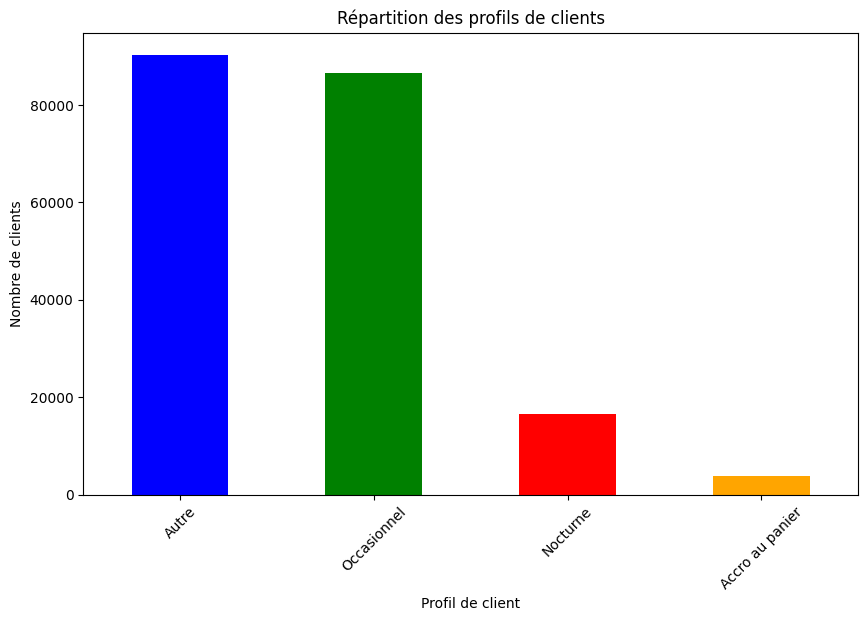

profil
Autre              90320
Occasionnel        86657
Nocturne           16609
Accro au panier     3772
Name: count, dtype: int64


In [28]:
# Définir les profils de clients
df_orders['nocturne'] = df_orders['order_hour_of_day'].between(20, 23) | df_orders['order_hour_of_day'].between(0, 6)
df_orders['occasionnel'] = df_orders['days_since_prior_order'] > 15
df_orders['accro_panier'] = df_orders['days_since_prior_order'] < 2

# Compter le nombre de clients pour chaque profil
profil_counts = df_orders.groupby('user_id').agg({
    'nocturne': 'sum',
    'occasionnel': 'sum',
    'accro_panier': 'sum'
}).reset_index()

# Définir les profils en fonction des critères
profil_counts['profil'] = profil_counts.apply(
    lambda row: 'Nocturne' if row['nocturne'] >= 3 else
    ('Occasionnel' if row['occasionnel'] >= 2 else
    ('Accro au panier' if row['accro_panier'] >= 3 else 'Autre')),
    axis=1
)

# Compter le nombre de clients pour chaque profil
profil_distribution = profil_counts['profil'].value_counts()

# Visualiser les résultats
plt.figure(figsize=(10, 6))
profil_distribution.plot(kind='bar', color=['blue', 'green', 'red', 'orange'])
plt.title('Répartition des profils de clients')
plt.xlabel('Profil de client')
plt.ylabel('Nombre de clients')
plt.xticks(rotation=45)
plt.show()

# Afficher les résultats
print(profil_distribution)

### ANTOINE : Quel article les clients ajoutent-ils en premier à leur panier ?

             product_name  first_product_count
0                  Banana                46970
1  Bag of Organic Bananas                33428
2      Organic Whole Milk                13120
3    Organic Strawberries                11673
4    Organic Hass Avocado                10212
5    Organic Baby Spinach                 9834
6         Organic Avocado                 9516
7            Spring Water                 7159
8            Strawberries                 6928
9     Organic Raspberries                 6183


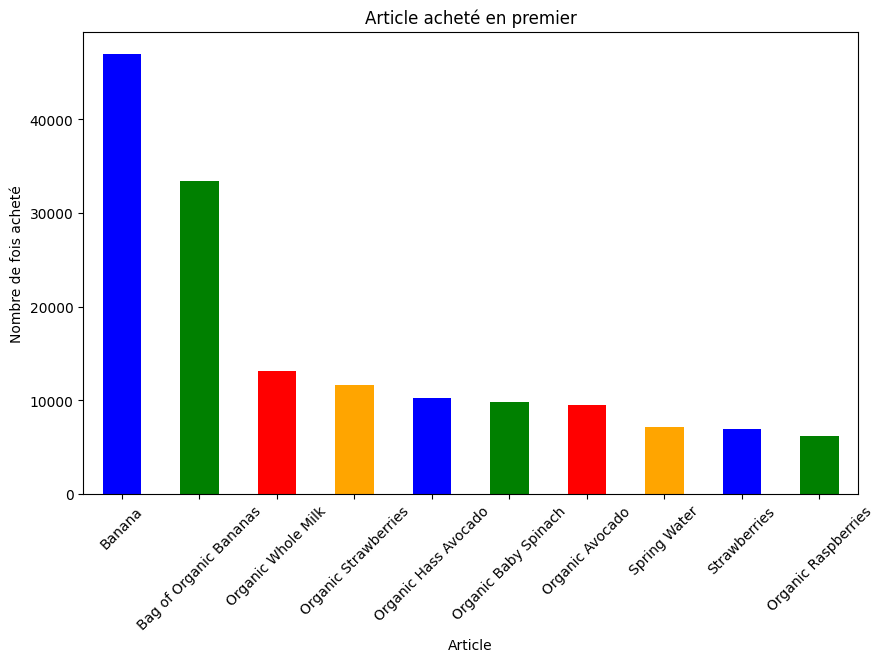

In [29]:
# Identifier le produit le plus souvent acheté en premier
df_order_products["first_product"] = df_order_products.groupby("order_id")["add_to_cart_order"].transform("min") == df_order_products["add_to_cart_order"]

# Compter le nombre de fois que chaque produit a été acheté en premier
first_product_counts = df_order_products[df_order_products["first_product"]].groupby("product_id").size().reset_index(name="first_product_count")

# Trier les produits par nombre de fois achetés en premier et prendre les 10 premiers
top_first_products = first_product_counts.sort_values(by="first_product_count", ascending=False).head(10)
# Ajouter les noms des produits
top_first_products = top_first_products.merge(df_products[["product_id", "product_name"]], on="product_id", how="left")

# Afficher les résultats
print(top_first_products[["product_name", "first_product_count"]])

# Visualiser les résultats
plt.figure(figsize=(10, 6))
top_first_products.set_index("product_name")["first_product_count"].plot(kind='bar', color=['blue', 'green', 'red', 'orange'])
plt.title('Article acheté en premier')
plt.xlabel('Article')
plt.ylabel('Nombre de fois acheté')
plt.xticks(rotation=45)
plt.show()

### ANTOINE : Quels produits ont le plus de chances d’être commandés à nouveau ?

                                         product_name  total_orders  \
0                              Purified Water, 9.5pH+           124   
1                                  Puffed Corn Cereal            71   
2                              Homestyle Orange Juice           135   
3                                Nearly Naked Popcorn            58   
4                                                 TAB            63   
5   Fragrance Free Clay with Natural Odor Eliminat...            55   
6        Superfood Cranberry, Almond & Lucuma Seedbar            67   
7                                Lo-Carb Energy Drink           221   
8                     Half And Half Ultra Pasteurized          1224   
9                      Organic Homogenized Whole Milk          1643   
10                               Wheat Sandwich Bread           416   
11                           Alimentum Infant Formula            56   
12                                   Ale, Hop Stoopid            63   
13    

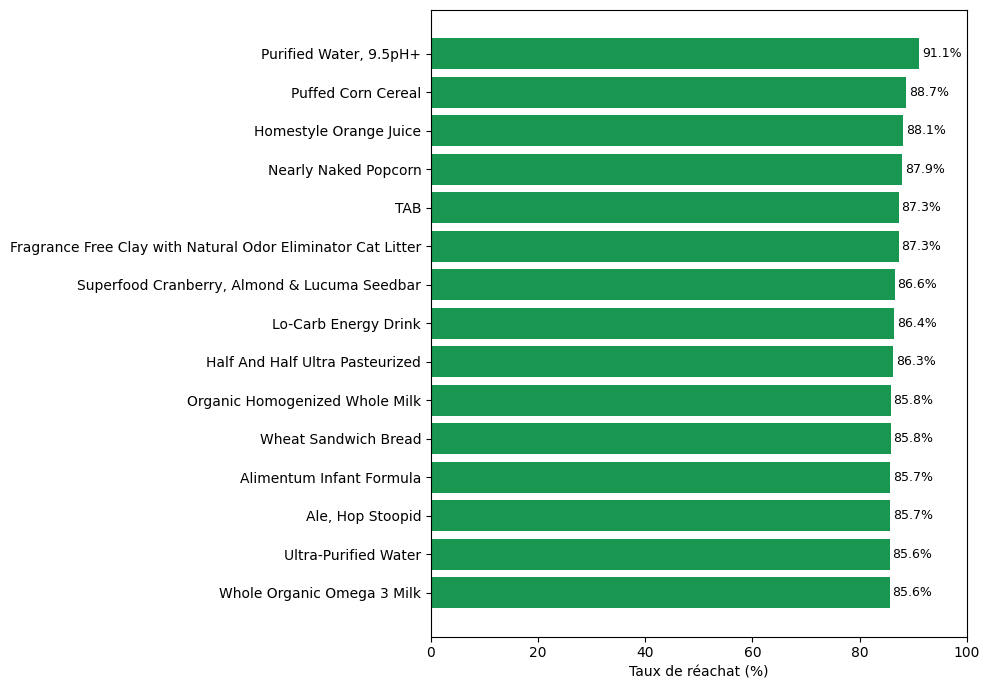

In [ ]:
# Calculer le taux de réachat par produit
reorder_stats = df_order_products.groupby('product_id').agg(
    total_orders=('reordered', 'count'),
    total_reorders=('reordered', 'sum')
).reset_index()

# Calculer le taux de réachat (en %)
reorder_stats['reorder_rate'] = reorder_stats['total_reorders'] / reorder_stats['total_orders']

# Filtrer les produits avec suffisamment de commandes pour être statistiquement fiables
reorder_stats = reorder_stats[reorder_stats['total_orders'] >= 50]

# Trier par taux de réachat et prendre les 15 meilleurs
top_reordered = reorder_stats.sort_values('reorder_rate', ascending=False).head(15)

# Ajouter les noms des produits
top_reordered = top_reordered.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')

# Afficher les résultats
print(top_reordered[['product_name', 'total_orders', 'total_reorders', 'reorder_rate']])

# Visualiser les résultats — graphique horizontal pour lisibilité des noms
fig, ax = plt.subplots(figsize=(10, 7))

colors = plt.cm.RdYlGn(np.linspace(0.4, 0.9, len(top_reordered)))
bars = ax.barh(
    top_reordered['product_name'],
    top_reordered['reorder_rate'] * 100,
    color=colors[-1]
)

# Ajouter les valeurs sur les barres
for bar in bars:
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():.1f}%', va='center', fontsize=9)

plt.title('% de chances de réachat par produit')
ax.set_xlabel('Taux de réachat (%)')
ax.set_xlim(0, 100)
ax.invert_yaxis()
plt.tight_layout()
plt.show()